# CNC Guard — 2. Fasea: Aurreprozesatzea eta Entrenamendua

**AABD Espezializazioa · 5071, 5072, 5073 moduluak**

Helburua: `ai4i2020_train.csv` datuetatik hutsegiteak iragarriko dituen eredu bat entrenatu eta `models/cnc_failure_model.pkl` gisa gorde.

## 1. Liburutegiak eta Karga

Beharrezko liburutegiak inportatu eta datuak kargatu.

In [ ]:
## install those
# imblearn==0.0
# matplotlib==3.11.2
# seaborn==0.13.2

In [27]:
# Liburutegiak inportatu
# ZURE KODEA HEMEN
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score,precision_recall_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [28]:
# Datuak kargatu
# df = ...
# ZURE KODEA HEMEN
df = pd.read_csv('../data/ai4i2020_train.csv')

print(df)

     machine_id machine_type  air_temp_K  process_temp_K   rpm  torque_Nm  \
0       CNC-024            M       302.0           310.9  1456       47.2   
1       CNC-011            M       297.0           308.3  1399       46.4   
2       CNC-030            M       301.0           311.6  1357       45.6   
3       CNC-050            L       298.9           309.8  1411       56.3   
4       CNC-040            L       297.1           308.5  1733       28.7   
...         ...          ...         ...             ...   ...        ...   
7995    CNC-042            L       296.1           306.7  1409       42.8   
7996    CNC-043            L       302.7           311.1  1440       39.5   
7997    CNC-003            H       300.3           311.5  1464       41.0   
7998    CNC-042            L       301.7           311.2  1517       42.4   
7999    CNC-039            L       298.7           309.7  1462       46.8   

      tool_wear_min  machine_failure  failure_TWF  failure_HDF  failure_PWF

## 2. EDA — Datu-azterketa

Aztertu:
- Zutabe motak eta balioen barrutiak
- **Klase-banaketa**: zenbat hutsegite dute makinek? Zenbat dabiltza funtzionamendu egokian?
- Ezaugarrien arteko korrelazioa bilatu

> Galdera: klase-banaketa desorekatuak zein doiketa suposatzen d(it)u ereduan?

Zutabe motak
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   machine_id       8000 non-null   str    
 1   machine_type     8000 non-null   str    
 2   air_temp_K       8000 non-null   float64
 3   process_temp_K   8000 non-null   float64
 4   rpm              8000 non-null   int64  
 5   torque_Nm        8000 non-null   float64
 6   tool_wear_min    8000 non-null   int64  
 7   machine_failure  8000 non-null   int64  
 8   failure_TWF      8000 non-null   int64  
 9   failure_HDF      8000 non-null   int64  
 10  failure_PWF      8000 non-null   int64  
 11  failure_OSF      8000 non-null   int64  
 12  failure_RNF      8000 non-null   int64  
dtypes: float64(3), int64(8), str(2)
memory usage: 812.6 KB

Balioen barrutiak
        air_temp_K  process_temp_K          rpm    torque_Nm  tool_wear_min  \
count  8000.000000     8000.000000  8000.00

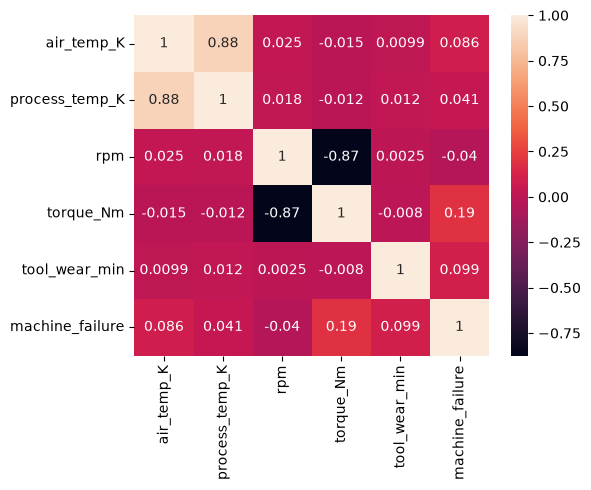

In [29]:
# EDA
# ZURE KODEA HEMEN
print("Zutabe motak")
df.info()

print("\nBalioen barrutiak")
# df.describe()
print(df.describe())

print("\nKlase banaketa")

print("FAIL / WORK")
fail = df[df['machine_failure'] > 0]
work = df[df['machine_failure'] <= 0]

print(f"{len(fail)} / {len(work)}")
print(f"% of fail: {df['machine_failure'].mean() * 100}")

print("\nKorrelazioak")
df_corr = df.loc[:, ~df.columns.str.startswith("failure_")]
print(df_corr.corr(numeric_only=True))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df_corr.corr(numeric_only=True), annot=True, ax=ax)
plt.tight_layout()
plt.show()

Un caso de clases desbalanceadas como este utilizan ajustes para tener una mejor precisión, por ejemplo en nuestro caso:
- Usar "stratify=y" al hacer uso de train_test_split, para que la clase por la que se separan los datos (en este caso machine_failure) utilicen la misma proporción de diferencia tanto en el valor de train como el de test.
- Utilizar método de rebalanceo en el entrenamiento, como SMOTE (crear datos sintéticos para igualar las clases) o class_weight (hacer que las clases tengan el mismo peso dándole a cada valor de la clase minoritaria su equivalente en proporción de diferencia con la clase mayoritaria).
- Evaluación de ajustes utilizando classification_report y similares.
- Ajuste de umbral de decisión, reduciéndolo el 0,5 que usa por defecto.

## 3. Aurreprozesatzea

Prestatu datuak entrenamendurako:
- Klase-desoreka tratatu (aukeratu ikuspegia eta **justifikatu**)
- (Aukerakoa) Feature engineering: ezaugarri artifizialak sortu,...

> Aukera posibleak?

In [30]:
# Preprocessing
# ZURE KODEA HEMEN
# TYPE_MAP = {"L": 0, "M": 1, "H": 2}

df_fltr = df.loc[:, ~df.columns.str.startswith("failure_")].drop('machine_id', axis=1)
# df_fltr['type_id'] = df_fltr['machine_type'].map(TYPE_MAP)
df_fltr['air_temp_C'] = df_fltr['air_temp_K'] - 273.15
df_fltr['process_temp_C'] = df_fltr['process_temp_K'] - 273.15
df_fltr['machine_failure'] = df_fltr['machine_failure'].astype(bool)
# df_fltr = df_fltr.drop('machine_type', axis=1).drop('air_temp_K', axis=1).drop('process_temp_K', axis=1)
df_fltr = df_fltr.loc[:, ~df_fltr.columns.str.endswith("temp_K")]
# .drop('machine_type', axis=1)
df_fltr['temp_diff'] = df_fltr['process_temp_C'] - df_fltr['air_temp_C']
df_fltr['power_est'] = df_fltr['torque_Nm'] * df_fltr['rpm'] * 2 * np.pi / 60

assert df_fltr.isna().sum().sum() == 0, "Hay NaN: ¿machine_type con valores inesperados?"
print("Features:", df_fltr.columns.drop('machine_failure').tolist())

print(df_fltr.groupby("machine_failure")[["temp_diff", "power_est"]]
        .agg(["min", "median", "max"]).round(1))
print(df_fltr.groupby("machine_type")["machine_failure"].agg(["count", "mean"]).round(4))

y_tmp = df_fltr['machine_failure']
print(y_tmp.value_counts())
print(f"Fallos: {y_tmp.mean()*100:.2f}% | proporción sin fallo/fallo: {(y_tmp == 0).sum() / (y_tmp == 1).sum():.1f} a 1")

Features: ['machine_type', 'rpm', 'torque_Nm', 'tool_wear_min', 'air_temp_C', 'process_temp_C', 'temp_diff', 'power_est']
                temp_diff              power_est                 
                      min median   max       min  median      max
machine_failure                                                  
False                 7.6    9.8  12.1    3515.0  6244.4   8998.0
True                  7.6    9.3  12.0    1148.4  7559.5  10469.9
              count    mean
machine_type               
H               789  0.0203
L              4830  0.0408
M              2381  0.0244
machine_failure
False    7729
True      271
Name: count, dtype: int64
Fallos: 3.39% | proporción sin fallo/fallo: 28.5 a 1


**Klase desoreka tratatu**

*Opciones*:
- class_weight: hace que ambas clases tengan el mismo peso total aunque haya distinta cantidad, sin modificar los datos.
- SMOTE: crea fallos sintéticos por interpolación hasta igualar las clases.
- Sobremuestreo aleatorio: duplica fallos existentes; favorece que el modelo memorice esas filas.
- Submuestreo: elimina filas de la clase mayoritaria; habría que descartar unas 7.400 filas y perder casi toda la información.
- Ajuste del umbral de decisión: no modifica lo que aprende el modelo, solo el punto de corte con el que una probabilidad se convierte en alerta.

*Elección*: class_weight="balanced" es la opción elegida para poder mantener coherencia en datos categóricos como type_id (el cual SMOTE puede generar un dato equivocado) y que ambas clases tengan el mismo peso total (siendo que 1 fallo tiene el peso equivalente a 28 no fallos), además que se mantienen los 8000 datos originales.

**Feature engineering**

- Cambio de unidad de medida en las temperaturas, pasando de Kelvin a Celsius para una mejor comprensión de nuestra parte en los gráficos de Kibana
- temp_diff: las temperaturas tienen una correlación de 0.876, este valor ayuda a medir el calentamiento real del proceso
- power_est: rpm y torque_Nm tienen una correlación negativa de −0,874 y su producto es la potencia en vatios.
- Cambio de machine_failure de int a boolean

- Se decidió excluir las variables 'failure_*' ya que tienen mucha relación con el fallo (fuga de datos), mientras 'machine_failure' es la etiqueta, no una variable de entrada. También se excluyó machine_id ya que es el identificador y no una medida para el entrenamiento.

## 4. Train / Validation Zatiketa

Garrantzitsua: `stratify=y` parametroa erabili klase-proportzioak mantentzeko.

In [31]:
# FEATURES aldagaia definitu — scoring-api-ak espero duen orden berdinean!
zenbakizkoak = ['air_temp_C', 'process_temp_C', 'temp_diff', 'rpm', 'torque_Nm', 'power_est', 'tool_wear_min']
kategorikoak = ['machine_type']
FEATURES = kategorikoak + zenbakizkoak

# Train/val zatitu
# ZURE KODEA HEMEN

X = df_fltr[FEATURES]
y = df_fltr['machine_failure']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 5. Entrenamendua

Eredu bat (gutxienez) entrenatu. Aukerakoa: hainbat eredu konparatu.

In [32]:
# Entrenamendua
# ZURE KODEA HEMEN
preprocessing = ColumnTransformer(transformers=[
    ("zenbak", Pipeline([
        ("bete", SimpleImputer(strategy="median")),
        ("eskala", StandardScaler())
    ]), zenbakizkoak),
    ("kateg", Pipeline([
        ("bete", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), kategorikoak),
])

pipe_cw = Pipeline([
    ("preprocessing", preprocessing),
    ("rf", RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1))
])

pipe_cw.fit(X_train, y_train)

cw_pred = pipe_cw.predict(X_test)
cw_prob = pipe_cw.predict_proba(X_test)[:, 1]

print("Class weight:")
print(f"Recall: {recall_score(y_test, cw_pred):.4f}")
print(f"Precision: {precision_score(y_test, cw_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, cw_prob):.4f}")

pipe_smote = ImbPipeline([
    ("preprocessing", clone(preprocessing)),
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

pipe_smote.fit(X_train, y_train)

smt_pred = pipe_smote.predict(X_test)
smt_prob = pipe_smote.predict_proba(X_test)[:, 1]

print("\nSMOTE:")
print(f"Recall: {recall_score(y_test, smt_pred):.4f}")
print(f"Precision: {precision_score(y_test, smt_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, smt_prob):.4f}")

Class weight:
Recall: 0.7593
Precision: 0.8913
ROC-AUC: 0.9793

SMOTE:
Recall: 0.8333
Precision: 0.6818
ROC-AUC: 0.9617


## 6. Ebaluazioa

Ebaluatu honako metrikekin:
- `classification_report` — precision, **recall**, f1-score
- `confusion_matrix` — bistaratu eta interpretatu
- `roc_auc_score`

> Zergatik da recall garrantzitsuagoa precision baino kasu honetan?

              precision    recall  f1-score   support

       False       0.99      1.00      0.99      1546
        True       0.89      0.76      0.82        54

    accuracy                           0.99      1600
   macro avg       0.94      0.88      0.91      1600
weighted avg       0.99      0.99      0.99      1600



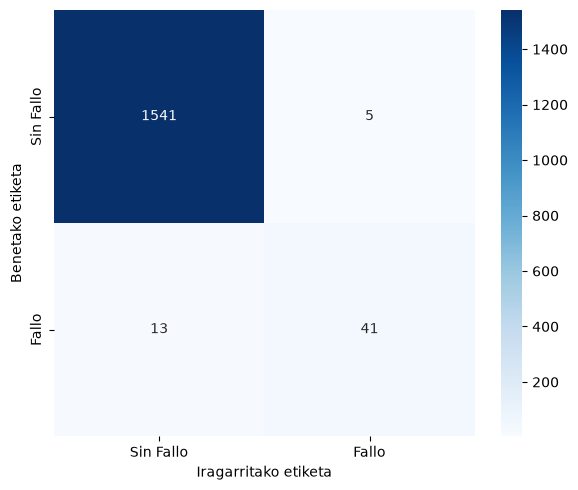

ROC-AUC score: 0.9793
              precision    recall  f1-score   support

       False       0.99      0.99      0.99      1546
        True       0.68      0.83      0.75        54

    accuracy                           0.98      1600
   macro avg       0.84      0.91      0.87      1600
weighted avg       0.98      0.98      0.98      1600



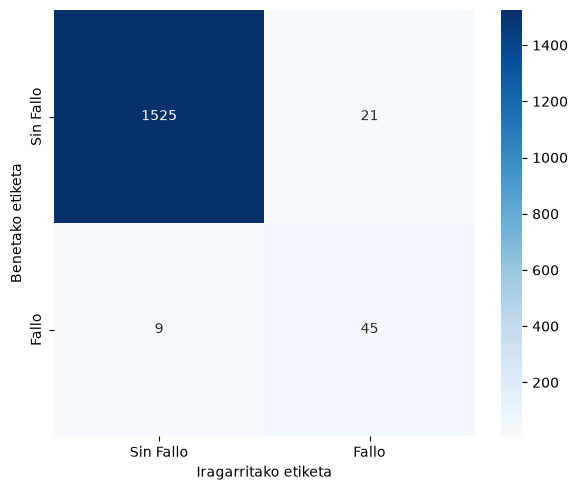

ROC-AUC score: 0.9617


In [33]:
# Ebaluazioa
# ZURE KODEA HEMEN

y_pred = pipe_cw.predict(X_test)
y_prob = pipe_cw.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues", xticklabels=["Sin Fallo", "Fallo"], yticklabels=["Sin Fallo", "Fallo"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()

print(f'ROC-AUC score: {roc_auc_score(y_test, y_prob):.4f}')

y_smote_pred = pipe_smote.predict(X_test)
y_smote_prob = pipe_smote.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_smote_pred))

cm = confusion_matrix(y_test, y_smote_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues", xticklabels=["Sin Fallo", "Fallo"], yticklabels=["Sin Fallo", "Fallo"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()

print(f'ROC-AUC score: {roc_auc_score(y_test, y_smote_prob):.4f}')

Para nosotros el recall es más importante a tener en cuenta porque se utiliza para detectar los falsos negativos, cuando una máquina dice estar bien pero no lo está, aunque claramente no significa que la precisión es irrelevante, al cambiar el umbral de decisión decidimos que entre nuestros dos principales métodos de tratamiento de desbalanceo de clases aquel que nos da una mejor respuesta es el class_weight, porque aunque tengan un recall similar la cantidad total de predicciones erróneas es menor.

## 6b. Atalasearen Doikuntza (Threshold Tuning)

Atalase lehenetsiak (0.5) Negatibo Faltsu (FN) gehiegi uzten baditu, saiatu atalasea jaisten (adib. 0.20 edo 0.15):
- Erabili predict_proba probabilitateak lortzeko.
- Marraztu Precision-Recall kurba (PrecisionRecallDisplay) atalase optimoa aukeratzeko.
- Aplikatu atalase berria eta atera berriro classification_report eta confusion_matrix.

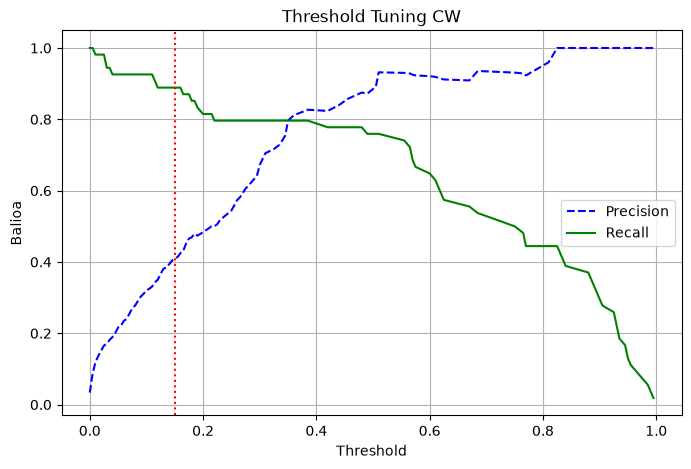

              precision    recall  f1-score   support

       False       1.00      0.96      0.98      1546
        True       0.41      0.89      0.56        54

    accuracy                           0.95      1600
   macro avg       0.70      0.92      0.77      1600
weighted avg       0.98      0.95      0.96      1600



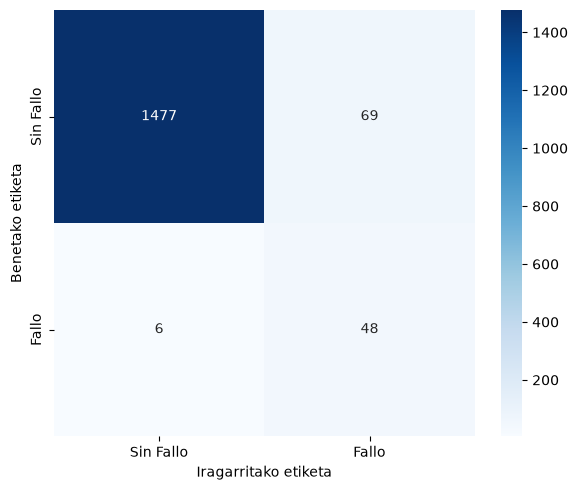

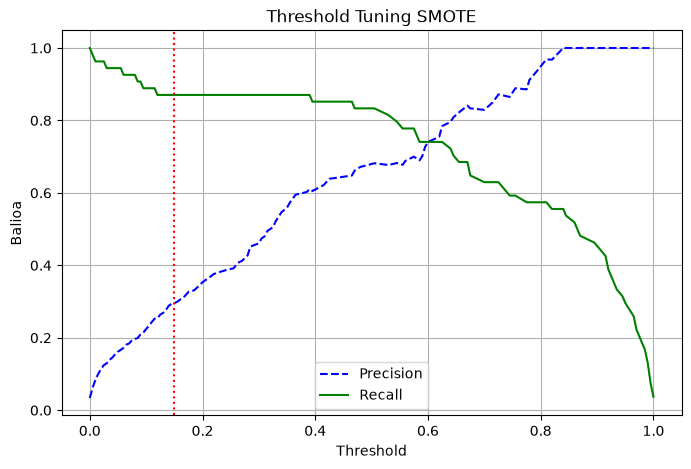

              precision    recall  f1-score   support

       False       1.00      0.93      0.96      1546
        True       0.30      0.87      0.44        54

    accuracy                           0.93      1600
   macro avg       0.65      0.90      0.70      1600
weighted avg       0.97      0.93      0.94      1600



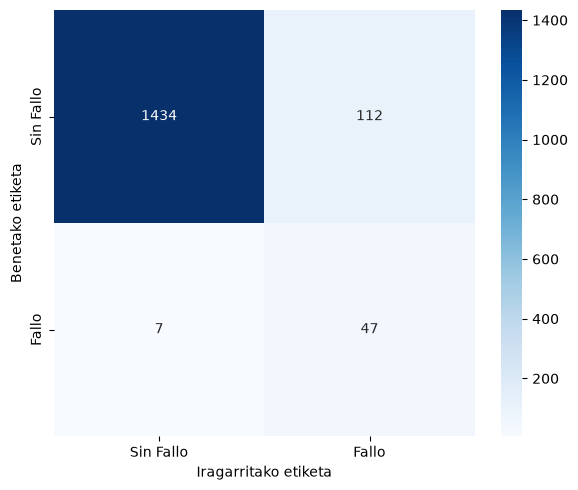

In [34]:
# Atalasearen Doikuntza (Threshold Tuning)
# y_prob = model.predict_proba(X_val)[:, 1]
# ZURE KODEA HEMEN
ATALASEA = 0.15

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions[:-1], "--b", label="Precision")
plt.plot(thresholds, recalls[:-1], "g-", label="Recall")
plt.xlabel('Threshold')
plt.ylabel('Balioa')
plt.title("Threshold Tuning CW")
plt.legend(loc="best")
plt.grid(True)
plt.axvline(ATALASEA, color="red", ls=":")
plt.show()

y_iragarkia_doitua = (y_prob >= ATALASEA).astype(int)

print(classification_report(y_test, y_iragarkia_doitua))

cm = confusion_matrix(y_test, y_iragarkia_doitua)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues", xticklabels=["Sin Fallo", "Fallo"], yticklabels=["Sin Fallo", "Fallo"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()

precisions_smote, recalls_smote, thresholds_smote = precision_recall_curve(y_test, y_smote_prob)

plt.figure(figsize=(8,5))
plt.plot(thresholds_smote, precisions_smote[:-1], "--b", label="Precision")
plt.plot(thresholds_smote, recalls_smote[:-1], "g-", label="Recall")
plt.xlabel('Threshold')
plt.ylabel('Balioa')
plt.title("Threshold Tuning SMOTE")
plt.legend(loc="best")
plt.grid(True)
plt.axvline(ATALASEA, color="red", ls=":")
plt.show()

y_smote_iragarkia_doitua = (y_smote_prob >= ATALASEA).astype(int)

print(classification_report(y_test, y_smote_iragarkia_doitua))

cm = confusion_matrix(y_test, y_smote_iragarkia_doitua)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues", xticklabels=["Sin Fallo", "Fallo"], yticklabels=["Sin Fallo", "Fallo"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()

## 7. Eredua Gorde

Scoring-api-k `/models/cnc_failure_model.pkl` bilatu behar du.

In [35]:
# joblib.dump(model, '../models/cnc_failure_model.pkl')
# ZURE KODEA HEMEN
joblib.dump(pipe_cw, '../models/cnc_failure_model.pkl')

# Egiaztatu scoring-api-k ondo kargatzen duela:
# docker compose restart scoring-api
# curl http://localhost:8000/health  → 'model_loaded: true' ikusi behar da

['../models/cnc_failure_model.pkl']